In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("../data/processed/foods_cleaned.csv")
features = ["Protein", "Fat", "Carbs", "Fibre"]
X = df[features].copy()
print("Feature matrix:", X.shape)
X.head()

Feature matrix: (5774, 4)


,Protein,Fat,Carbs,Fibre
0,9.544150,15.704700,5.911000,0.117000
1,4.074000,2.799000,5.293000,1.149000
2,6.760000,2.800000,8.290000,1.000000
3,8.550000,21.238000,38.623000,1.994000
4,5.457754,1.909353,9.258948,1.664603


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

scaled_df.describe().round(2)

,Protein,Fat,Carbs,Fibre
count,5774.00,5774.00,5774.00,5774.00
mean,-0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-1.03,-0.62,-0.85,-0.51
25%,-0.82,-0.58,-0.82,-0.51
50%,-0.31,-0.37,-0.44,-0.32
75%,0.70,0.17,0.48,0.08
max,7.20,5.58,2.89,16.19


In [4]:
print("Means:")
print(scaled_df.mean().round(2))
print("Standard deviations:")
print(scaled_df.std(ddof=0).round(2))

Means:
Protein   -0.0
Fat       -0.0
Carbs      0.0
Fibre     -0.0
dtype: float64
Standard deviations:
Protein    1.0
Fat        1.0
Carbs      1.0
Fibre      1.0
dtype: float64


In [5]:
k_values = range(2, 11)
inertia = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_scores.append(score)

results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia,
    "Silhouette": silhouette_scores
})

display(results)

,K,Inertia,Silhouette
0,2,16842.326337,0.385443
1,3,12425.542257,0.398401
2,4,8796.694563,0.466066
3,5,6455.039963,0.489304
4,6,5666.013936,0.477937
5,7,5033.536918,0.480603
6,8,4477.122633,0.421732
7,9,3993.675485,0.446829
8,10,3681.381701,0.402568


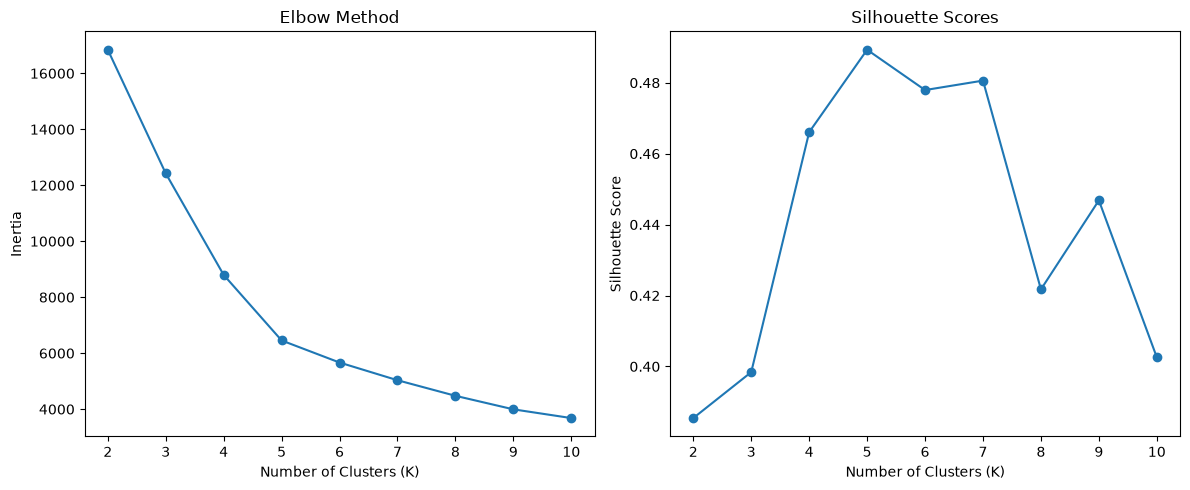

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(
    results["K"],
    results["Inertia"],
    marker="o"
)

axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    results["K"],
    results["Silhouette"],
    marker="o"
)

axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()